# Readout mitigation

**Question:** Can calibration improve our estimate of the pairwise cost after measurement?

I compare the raw estimate, a local readout-corrected estimate and a raw estimate with the same total shot budget as the corrected one. The correction assumes independent readout errors. It estimates a mean cost; it does not create corrected samples or an improved optimum frequency.

## 1. Load and compile the fixed circuit

The [setup notebook](hardware_setup.ipynb) provides the reads, angles and cost. I use one compiled circuit so calibration and target samples use the same physical measurement mapping.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


In [2]:
if backend.num_qubits > 16:
    raise ValueError('Choose a smaller simulated backend for this study.')
manager = generate_preset_pass_manager(
    backend=backend, optimization_level=2, seed_transpiler=71,
)
compiled = manager.run(make_circuit())
measurement_map = {
    compiled.find_bit(item.clbits[0]).index: compiled.find_bit(item.qubits[0]).index
    for item in compiled.data if item.operation.name == 'measure'
}
if set(measurement_map) != set(range(n)):
    raise ValueError('Expected one final measurement for each SNP.')
print('Classical SNP bit → measured physical qubit:', measurement_map)
print('Compiled resources:', resources(compiled))

Classical SNP bit → measured physical qubit: {0: 0, 1: 4, 2: 3, 3: 1, 4: 2}
Compiled resources: {'2q gates': 29, '2q depth': 24, 'depth': 49}


## 2. Build two calibration circuits

I prepare all-zero and all-one states and measure the same physical qubits into the same classical bits as the target. The all-one preparation uses X gates, so its errors can affect calibration.

In [3]:
calibrations = []
for prepared in [0, 1]:
    circuit = QuantumCircuit(backend.num_qubits, n)
    if prepared:
        for qubit in measurement_map.values():
            circuit.x(qubit)
    for bit, qubit in measurement_map.items():
        circuit.measure(qubit, bit)
    calibrations.append(circuit)

calibration_manager = generate_preset_pass_manager(
    backend=backend, optimization_level=0,
    initial_layout=list(range(backend.num_qubits)), seed_transpiler=71,
)
calibrations = [calibration_manager.run(circuit) for circuit in calibrations]
for circuit in calibrations:
    actual = {circuit.find_bit(item.clbits[0]).index: circuit.find_bit(item.qubits[0]).index
              for item in circuit.data if item.operation.name == 'measure'}
    assert actual == measurement_map
print('Both calibrations use the target measurement map.')

Both calibrations use the target measurement map.


## 3. Estimate local readout errors

For each bit, `local_matrices` builds a 2 × 2 table of calibration probabilities: rows are observed values and columns are prepared values. It refuses to invert a table if the correction would be too unstable.

`corrected_cost` uses the inverse tables to adjust the measured values for each SNP pair. It then combines those adjusted pair values with the agree/disagree votes and averages over all shots. The result is an estimated mean cost before readout errors; it does not change individual bitstrings. The method assumes independent readout errors, which may not hold in practice.

In [4]:
def local_matrices(zero_counts, one_counts):
    response = np.zeros((n, 2, 2))
    for prepared, counts in enumerate([zero_counts, one_counts]):
        total = sum(counts.values())
        for key, count in counts.items():
            for bit, observed in enumerate(key.replace(' ', '')[::-1]):
                response[bit, int(observed), prepared] += count / total
    if max(np.linalg.cond(response)) > 1e6:
        raise ValueError('Calibration is too unstable to invert.')
    return response


def corrected_cost(counts, response):
    # Estimate each pair's Z_i Z_j value from the observed bits.
    z = np.array([1., -1.]) @ np.linalg.inv(response)
    total = sum(counts.values())
    estimate = 0.
    for key, count in counts.items():
        bits = [int(bit) for bit in key.replace(' ', '')[::-1]]
        for i, j in itertools.combinations(range(n), 2):
            offset = (agree[i, j] + disagree[i, j]) / 2
            weight = (disagree[i, j] - agree[i, j]) / 2
            estimate += count * (offset + weight * z[i, bits[i]] * z[j, bits[j]])
    return estimate / total

## 4. Create a simulator reference before readout errors

For this small simulated study, I remove the final measurements and use a density matrix to compute the exact mean after gate noise but before readout. This reference would not usually be known on real hardware. Density-matrix memory grows as 4^n, so I skip it above ten backend qubits.

In [5]:
reference_cost = None
if backend.num_qubits <= 10:
    before_readout = compiled.remove_final_measurements(inplace=False)
    before_readout.save_probabilities_dict()
    reference_sim = AerSimulator.from_backend(
        backend, method='density_matrix', max_parallel_threads=1,
    )
    probabilities = reference_sim.run(before_readout).result().data(0)['probabilities']
    reference_cost = sum(
        probability * cost([(state >> measurement_map[bit]) & 1 for bit in range(n)])
        for state, probability in probabilities.items()
    )
    print('Exact simulated pre-readout mean cost:', round(reference_cost, 4))
else:
    print('Exact pre-readout reference skipped: density-matrix simulation grows as 4^n.')

Exact simulated pre-readout mean cost: 8.8542


## 5. Compare equal shot budgets

Each repeat uses 2,048 target shots and two calibrations of 1,024 shots each by default. The independent raw comparison uses the same target-plus-calibration budget. The exact simulated reference uses no shots and is reported separately.

In [6]:
calibration_shots = 1024
repeats = 5
simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
results = []
for repeat in range(repeats):
    calibration_result = simulator.run(
        calibrations, shots=calibration_shots, seed_simulator=7000 + repeat,
    ).result()
    response = local_matrices(calibration_result.get_counts(0), calibration_result.get_counts(1))
    target = simulator.run(compiled, shots=shots,
                           seed_simulator=8000 + repeat).result().get_counts()
    equal_shots = shots + 2 * calibration_shots
    raw_equal = simulator.run(compiled, shots=equal_shots,
                              seed_simulator=9000 + repeat).result().get_counts()
    results.append({'repeat': repeat, 'raw': score(target)['mean cost'],
                    'local corrected': corrected_cost(target, response),
                    'raw equal budget': score(raw_equal)['mean cost']})
readout_results = pd.DataFrame(results)
display(readout_results.round(4))
print('Shots per corrected arm:', equal_shots,
      '| shots per equal-budget raw arm:', equal_shots,
      '| pre-readout reference: density-matrix simulation (no shots)')

,repeat,raw,local corrected,raw equal budget
0,0,9.4033,8.9138,9.2419
1,1,9.3574,8.7989,9.4153
2,2,9.3442,8.8548,9.2732
3,3,9.2964,8.7848,9.2969
4,4,9.5503,9.0740,9.4834


Shots per corrected arm: 4096 | shots per equal-budget raw arm: 4096 | pre-readout reference: density-matrix simulation (no shots)


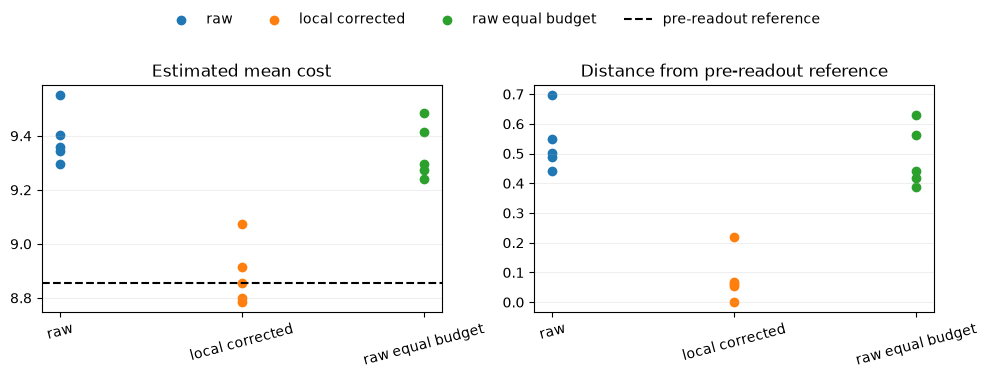

In [7]:
methods = ['raw', 'local corrected', 'raw equal budget']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for index, name in enumerate(methods):
    axes[0].scatter([index] * repeats, readout_results[name], label=name)
    if reference_cost is not None:
        axes[1].scatter([index] * repeats, abs(readout_results[name] - reference_cost))
if reference_cost is not None:
    axes[0].axhline(reference_cost, color='black', linestyle='--', label='pre-readout reference')
else:
    axes[1].text(.5, .5, 'Reference skipped', ha='center', transform=axes[1].transAxes)
for ax in axes:
    ax.set_xticks(range(len(methods)), methods, rotation=15)
    ax.grid(axis='y', alpha=.2)
axes[0].set_title('Estimated mean cost')
axes[1].set_title('Distance from pre-readout reference')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

## What did I find?

In the saved run, local readout correction brought the estimated mean cost closer to the simulated value before readout errors in all five repeats. It also did better on this measure than the raw comparison given the same total shot budget, including calibration shots.

This is a small simulator test, and the corrected values are estimates, not new bitstrings. The related [TREX-style test](hardware_trex.ipynb) and [M3 comparison](hardware_m3_readout.ipynb) are in this folder.